# 06 · Model Explainability with SHAP (Phase 6)
**Deliverable:** a SHAP-based explanation of the KenyaSMS Shield classifiers - *what does the model rely on, why did it score individual messages the way it did, where does it go wrong, and can we trust the explanation itself?*

### What this notebook does, in order
1. Rebuild the advanced binary and 3-class models under the **held-out protocol** (fitted on the training split only) and confirm they reproduce the published numbers.
2. Compute SHAP values and verify them (additivity; comparison with the app's current explanation).
3. **Global** explanations: importance bar chart, beeswarm, feature families, drill-downs into the top features.
4. **Local** explanations: waterfalls for a caught scam, a clean legit message, a false alarm and a missed scam.
5. **Error analysis** through SHAP: what distinguishes caught from missed scams and false alarms from correct passes.
6. The app's own example messages explained with the **deployed** model.
7. The **severity** (moderate vs high-risk) model.
8. **Stability** of the explanations across bootstrap refits, optional cross-check with the `shap` package, saved outputs, limitations.

### Protocol reminders
* Nothing here changes any model, threshold or reported metric. SHAP explains the models *as they are*.
* Held-out explanations use models fitted on the **515 training messages (+80 synthetic legit)** and explain the **128 test messages** they never saw. The deployed bundle was refitted on all data, so it is used only for the app examples in section 6.
* Explanations describe **what the model does with this dataset's labels**, not what makes a message fraudulent in the real world.

## 0. Setup and method decisions
| Choice | Decision | Reasoning |
|---|---|---|
| Models explained | Binary Logistic Regression (word 1-2-gram TF-IDF + char 2-5-gram TF-IDF + 28 rule-based features) and the 3-class severity Logistic Regression - the two models behind `app.py` | These are the deployed models; the baseline of notebooks 03/04 was already explained with coefficients. |
| SHAP algorithm | **Exact linear (interventional) SHAP**: `phi_i(x) = w_i * (x_i - mean_i)` | Both models are linear in the feature space, so this is exactly what `shap.LinearExplainer` returns - no sampling error. It is implemented in `src/explain.py` and cross-checked against the `shap` package when that is installed (section 8). A tree/kernel explainer would be slower *and* approximate. |
| Scale | **Log-odds** (logit) | The scale on which the model is additive. The deployed score is `sigmoid(logit)`; the 0.32 threshold is **-0.754** in log-odds. |
| Background distribution | The training data the model was fitted on (515 + 80 synthetic) | SHAP is always *relative to a reference*: a value says "compared with a typical training message". The expected value `E[f(x)]` is the mean training logit. |
| Explained set | The 128 held-out test messages | Explaining data the model never saw avoids describing memorised behaviour. |
| Known caveat | Independent-feature assumption | TF-IDF n-grams are strongly correlated (the word `free` and the char n-gram `_free` overlap), so credit is **split** across overlapping features and a single concept looks weaker than it is. Section 3 therefore also reports importance by feature *family*. |
| No interaction analysis | By design | An additive model has no feature interactions (SHAP interaction values are exactly zero), and for a linear model a SHAP dependence plot is just a straight line - so neither is shown. |

In [1]:
import sys; sys.path.insert(0, '..')           # makes src/ importable when the notebook runs from notebooks/
import json, re, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt, joblib
from scipy.stats import spearmanr
from sklearn.metrics import roc_auc_score
from src.preprocessing import load_raw, clean_dataset, model_text, LEXICONS, WORD_RE
from src.advanced import build_advanced_pipeline, AdvancedFeatures, BUNDLE_PATH, KENYA_PATTERNS, ROOT
from src.explain import (linear_shap, crosscheck_with_shap, plot_bar, plot_beeswarm, plot_waterfall,
                         FAMILY_ORDER, FAMILY_COLORS, C_SCAM, C_LEGIT, C_GREY)

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', None, 'display.width', 220, 'display.max_colwidth', 110)
plt.rcParams.update({'figure.dpi': 110, 'axes.titlesize': 10, 'axes.labelsize': 9, 'font.size': 9})
FIG = ROOT / 'reports' / 'figures'; FIG.mkdir(parents=True, exist_ok=True)
def save(name): plt.savefig(FIG / f'{name}.png', dpi=150, bbox_inches='tight', facecolor='white')

THRESHOLD = 0.32                                       # deployed binary threshold (src/advanced.py)
THR_LOGIT = float(np.log(THRESHOLD / (1 - THRESHOLD))) # the same threshold on the log-odds scale
print(f'threshold {THRESHOLD}  ->  log-odds {THR_LOGIT:+.3f}')

threshold 0.32  ->  log-odds -0.754


### 1. Rebuild the models under the held-out protocol
Same preparation as `src.advanced.train_and_evaluate`. The assertion confirms we explain the model that produced the published ROC-AUC (0.9401).

In [2]:
# Same data preparation and split as src.advanced.train_and_evaluate (so the numbers match the evaluation report)
raw = load_raw(ROOT / 'data' / 'scam_detection_labeled.csv'); clean, _ = clean_dataset(raw)
clean['tier'] = clean['prelabel'].astype(str).str[0].astype(int)         # 0 legit, 1 moderate-risk, 2 high-risk
split = pd.read_csv(ROOT / 'data' / 'split.csv').drop_duplicates('text_key')[['text_key', 'split', 'group']]
d = clean.merge(split, on='text_key', how='inner', suffixes=('', '_split'))
tr = d[d.split == 'train'].reset_index(drop=True); te = d[d.split == 'test'].reset_index(drop=True)
syn = pd.read_csv(ROOT / 'data' / 'synthetic_legitimate_development.csv')  # 80 synthetic legit msgs: training augmentation only

Xtr = np.concatenate([tr.message_content.to_numpy(), syn.message_content.to_numpy()])
ytr = np.concatenate([tr.y.to_numpy(), np.zeros(len(syn), int)])
y3tr = np.concatenate([tr.tier.to_numpy(), np.zeros(len(syn), int)])
Xte, yte, y3te = te.message_content.to_numpy(), te.y.to_numpy(), te.tier.to_numpy()

binary = build_advanced_pipeline(False).fit(Xtr, ytr)       # held-out-protocol binary model (never saw the test set)
severity = build_advanced_pipeline(True).fit(Xtr, y3tr)     # held-out-protocol 3-class model

# sanity check: we are explaining the SAME model that produced the published held-out numbers
reported = json.load(open(ROOT / 'reports' / 'advanced_evaluation.json'))['binary_test']['roc_auc']
auc = roc_auc_score(yte, binary.predict_proba(Xte)[:, 1])
assert abs(auc - reported) < 1e-9, (auc, reported)
print(f'train {len(tr)} (+{len(syn)} synthetic legit) | test {len(te)} | scam share in test {yte.mean():.2f}')
print(f'binary ROC-AUC on test = {auc:.4f}  (matches reports/advanced_evaluation.json: {reported:.4f})')
print('feature space:', len(binary.named_steps["features"].get_feature_names_out()), 'features')

train 515 (+80 synthetic legit) | test 128 | scam share in test 0.59
binary ROC-AUC on test = 0.9401  (matches reports/advanced_evaluation.json: 0.9401)
feature space: 19349 features


### 2. Compute and verify the SHAP values
**Additivity** is the defining SHAP property: base value + sum of a message's SHAP values must equal the model output. Here it holds to machine precision (~1e-14), so the numbers below are exactly the model's arithmetic, not an approximation.

The outcome table uses the deployed threshold (0.32): 73 scams caught, 2 missed, 14 false alarms, 39 correct passes - the same confusion matrix as `reports/advanced_evaluation.json` (recall 0.973, precision 0.839).

In [3]:
sv = linear_shap(binary, Xtr, Xte)       # background = the training data the model was fitted on
te['score'] = sv.prob; te['pred'] = (te.score >= THRESHOLD).astype(int)
te['outcome'] = np.select([(te.y == 1) & (te.pred == 1), (te.y == 0) & (te.pred == 0), (te.y == 0) & (te.pred == 1)],
                          ['TP (scam caught)', 'TN (legit passed)', 'FP (false alarm)'], 'FN (missed scam)')
print(f'SHAP matrix: {sv.values.shape[0]} messages x {sv.values.shape[1]} features')
print(f'expected value E[f(x)] = {sv.base_value:+.3f} log-odds  (= score {100/(1+np.exp(-sv.base_value)):.0f}/100 for an "average" training message)')
print(f'additivity check  max |E[f] + sum(SHAP) - f(x)| = {sv.additivity_error():.1e}')
print(f'agrees with pipeline.decision_function: {np.allclose(sv.logit, binary.decision_function(Xte))}')
te.outcome.value_counts().to_frame('messages').T

SHAP matrix: 128 messages x 19349 features
expected value E[f(x)] = +0.187 log-odds  (= score 55/100 for an "average" training message)
additivity check  max |E[f] + sum(SHAP) - f(x)| = 7.1e-15
agrees with pipeline.decision_function: True


outcome,TP (scam caught),TN (legit passed),FP (false alarm),FN (missed scam)
messages,73,39,14,2


In [4]:
# What does SHAP add over the app's current "coefficient x feature value" explanation (src.advanced.explain_linear)?
w = binary.named_steps['clf'].coef_[0]
coefx = sv.data * w                                       # the existing explanation: ignores what is "normal"
rho = []
for i in range(len(te)):
    m_ = sv.data[i] != 0                                  # features present in the message
    rho.append(spearmanr(coefx[i][m_], sv.values[i][m_])[0])
print(f'per-message rank agreement between coef*x and SHAP over features present: median Spearman = {np.nanmedian(rho):.2f}')

i = te.index[te.outcome.str.startswith('TN')][te.loc[te.outcome.str.startswith('TN'), 'score'].argmin()]
print('\nclearest legit message:', te.message_content[i][:140].replace('\n', ' '))
o = np.argsort(-np.abs(sv.values[i]))[:8]
pd.DataFrame({'feature': sv.pretty[o], 'value x': sv.data[i, o].round(3),
              'coef x value (current app)': coefx[i, o].round(3), 'SHAP (vs average message)': sv.values[i, o].round(3)})

per-message rank agreement between coef*x and SHAP over features present: median Spearman = 0.97

clearest legit message: '“You will be made rich in every way so that you can be generous in every way. Such generosity produces thanksgiving to God👐To share this me


,feature,value x,coef x value (current app),SHAP (vs average message)
0,[lex_urgency],0.000,0.000,-0.398
1,[n_urls],0.000,0.000,-0.285
2,[n_emoji],0.233,-0.275,-0.258
3,[n_words_log],0.466,0.731,0.228
4,[lex_reply_stop],0.700,-0.232,-0.211
5,god,0.159,-0.186,-0.177
6,[n_chars_log],0.507,0.830,0.174
7,[lex_reward],0.000,0.000,-0.114


**Reading - what does SHAP add over the explanation the app shows today?** The app uses `coefficient x feature value`. Over the features that are *present* in a message the two rank features almost identically (median Spearman 0.97), so the existing explanation was not misleading. The difference is the **reference point**:

* `coefficient x value` is exactly **0** for a feature that is absent. SHAP says an absent feature can still be *evidence*: this devotional message has no urgency word (-0.40) and no link (-0.29), which is real evidence for "legit" because a typical training message carries them. The current app explanation cannot say "no link, no urgency, therefore reassuring".
* SHAP values are *relative to an average message* and sum to the score; coefficient x value is not anchored to anything.

## 3. Global explanations - what does the model rely on?
### 3.1 Importance (mean |SHAP|) and 3.2 beeswarm
The bar chart ranks features by their average absolute effect on the score. The beeswarm adds *direction and spread*: each dot is one test message, its horizontal position is the push on the scam log-odds, its colour is the feature's value (blue low, red high).

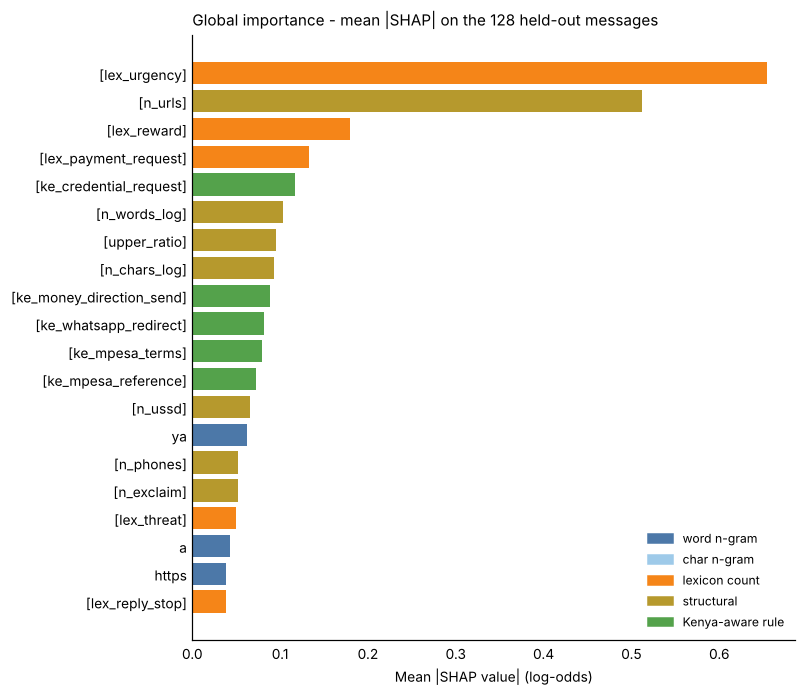

,feature,family,mean_abs_shap,mean_shap,present_in
0,[lex_urgency],lexicon count,0.654,0.044,0.234
1,[n_urls],structural,0.513,0.076,0.234
2,[lex_reward],lexicon count,0.180,0.004,0.227
3,[lex_payment_request],lexicon count,0.133,0.033,0.227
4,[ke_credential_request],Kenya-aware rule,0.117,-0.022,0.031
5,[n_words_log],structural,0.103,0.022,1.000
6,[upper_ratio],structural,0.096,-0.010,0.992
7,[n_chars_log],structural,0.093,0.019,1.000
8,[ke_money_direction_send],Kenya-aware rule,0.089,-0.019,0.125
9,[ke_whatsapp_redirect],Kenya-aware rule,0.081,-0.003,0.039


In [5]:
g = sv.global_importance()
fig, ax = plt.subplots(figsize=(7.4, 6.4))
plot_bar(sv, top=20, ax=ax); ax.set_title('Global importance - mean |SHAP| on the 128 held-out messages', loc='left')
plt.tight_layout(); save('shap_global_bar')
g.head(15)[['feature', 'family', 'mean_abs_shap', 'mean_shap', 'present_in']].round(3)

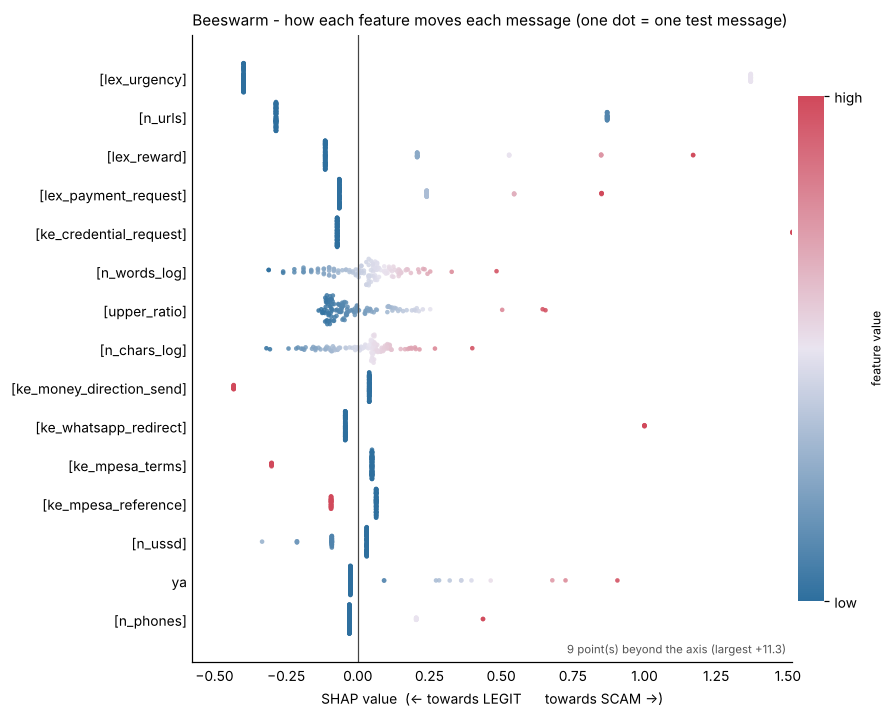

In [6]:
fig, ax = plt.subplots(figsize=(8.2, 6.6))
plot_beeswarm(sv, top=15, ax=ax); ax.set_title('Beeswarm - how each feature moves each message (one dot = one test message)', loc='left')
plt.tight_layout(); save('shap_beeswarm')

**Reading**
* **Two engineered features dominate.** `lex_urgency` (mean |SHAP| 0.65) and `n_urls` (0.51) are each at least ~3x larger than any other feature (next: 0.18) - together ~15% of all attribution mass, despite 19,349 features. Both are *present* in only ~23% of test messages, so most of their effect comes from a few messages pushing hard towards scam (red dots on the right) plus a constant small push towards legit for everyone without them (the blue stack at about -0.4 / -0.3).
* The next tier is the other lexicon counts (`lex_reward`, `lex_payment_request`) and the Kenya-aware rule `ke_credential_request` (PIN / OTP / password requests; present in only 3% of messages but a large push when it fires).
* `n_words_log`, `n_chars_log` and `upper_ratio` act as graded length/shouting signals (longer and louder -> more scam-leaning).
* Individual words and char n-grams matter one at a time much less (`ya`, `a`, `https` are the first to appear) - the text signal is spread over thousands of small contributions, which is why section 3.3 groups them.
* This agrees with the baseline study (notebook 04), where link count, urgency and threat wording were also the strongest coefficients - an independent confirmation, not a coincidence of method.

### 3.2b An outlier worth understanding
 One message has a SHAP value of about +11 log-odds for `n_urls`, far beyond everything else (the beeswarm axis is clipped and says so). The cell below shows why.

In [7]:
# The beeswarm shows one message with an enormous [n_urls] effect. Why?  Link COUNT is an unbounded linear feature.
from src.preprocessing import extract_hand_features
n_tr = np.array([extract_hand_features(t)['n_urls'] for t in Xtr]); n_te = np.array([extract_hand_features(t)['n_urls'] for t in Xte])
j = int(np.argmax(sv.values[:, list(sv.names).index('hand__n_urls')]))
w_urls = binary.named_steps['clf'].coef_[0][list(sv.names).index('hand__n_urls')]
print(f'links per message: training max = {n_tr.max():.0f}, test max = {n_te.max():.0f}')
print(f'test message #{j} has {n_te[j]:.0f} links -> scaled feature value {sv.data[j, list(sv.names).index("hand__n_urls")]:.2f} (largest value in training: {binary.named_steps["features"].transform(Xtr)[:, list(sv.names).index("hand__n_urls")].max():.2f}), '
      f'SHAP {sv.values[j, list(sv.names).index("hand__n_urls")]:+.1f} log-odds (weight {w_urls:.2f})')
print('without that message the largest [n_urls] effect is',
      f"{np.delete(sv.values[:, list(sv.names).index('hand__n_urls')], j).max():+.2f}")

links per message: training max = 3, test max = 10
test message #92 has 10 links -> scaled feature value 2.33 (largest value in training: 0.70), SHAP +11.3 log-odds (weight 4.95)
without that message the largest [n_urls] effect is +2.02


**Reading - a genuine model weakness found by SHAP.** The message contains 10 links; the training data never has more than 3. Link *count* is an unbounded linear feature, so the model extrapolates: 10 links is worth ~+11 log-odds, i.e. more than every other feature combined. Here the prediction is right (it is a scam), but the same mechanism means any message with many links gets a near-certain 100/100 regardless of the rest of its content. A cheap remedy to consider (not applied here, because it would change the model and its metrics): cap counts, e.g. `min(n_urls, 3)`, or use `log1p` as is already done for length.

### 3.3 Feature families
Because correlated n-grams share credit, a fairer view of *what kind of evidence* the model uses sums SHAP values within each family. Left: how much each family moves a typical message. Right: whether the family separates the classes (positive for true scams, negative for true legit).

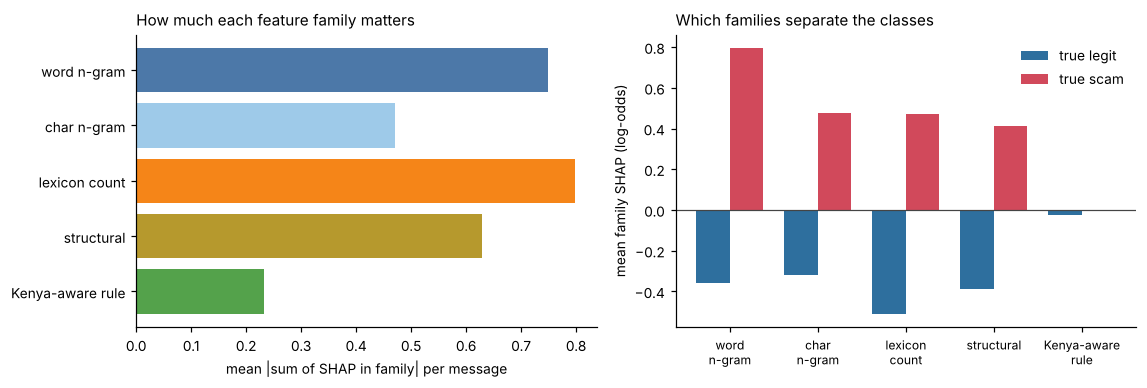

,mean |family SHAP|,true legit,true scam
word n-gram,0.749,-0.360,0.796
char n-gram,0.470,-0.320,0.474
lexicon count,0.798,-0.509,0.469
structural,0.629,-0.390,0.412
Kenya-aware rule,0.232,-0.024,-0.002


In [8]:
fc = sv.family_contribution()
by_class = fc.groupby(np.where(yte == 1, 'true scam', 'true legit')).mean().T[['true legit', 'true scam']]
total_abs = fc.abs().mean()
fig, ax = plt.subplots(1, 2, figsize=(10.5, 3.6))
ax[0].barh(total_abs.index[::-1], total_abs.values[::-1], color=[FAMILY_COLORS[f] for f in total_abs.index[::-1]])
ax[0].set_xlabel('mean |sum of SHAP in family| per message'); ax[0].set_title('How much each feature family matters', loc='left')
x = np.arange(len(FAMILY_ORDER)); wd = 0.38
ax[1].bar(x - wd/2, by_class['true legit'], wd, color=C_LEGIT, label='true legit')
ax[1].bar(x + wd/2, by_class['true scam'], wd, color=C_SCAM, label='true scam')
ax[1].axhline(0, color='#444', lw=.8); ax[1].set_xticks(x); ax[1].set_xticklabels([f.replace(' ', '\n') for f in FAMILY_ORDER], fontsize=8)
ax[1].set_ylabel('mean family SHAP (log-odds)'); ax[1].set_title('Which families separate the classes', loc='left'); ax[1].legend(frameon=False)
for a in ax:
    for s in ('top', 'right'): a.spines[s].set_visible(False)
plt.tight_layout(); save('shap_families')
pd.concat([total_abs.rename('mean |family SHAP|'), by_class], axis=1).round(3)

**Reading**
* The **7 lexicon counts** (0.80) and the **word n-grams** (0.75) are the strongest families, followed by structural features (0.63) and char n-grams (0.47).
* **The Kenya-aware rules are the weakest family** (0.23) and, importantly, barely separate the classes: mean family SHAP is -0.02 for legit and -0.00 for scam. On *this dataset* the model separates scams from legitimate messages mainly through generic promotion/subscription-scam cues (urgency, links, rewards, payment wording), not through M-Pesa-, bank- or reversal-specific cues. This is a statement about the data (it contains few M-Pesa fraud messages), not proof the Kenya-aware rules are useless - section 6 shows them driving the scores of the PIN/OTP examples.

### 3.4 Drilling into the top features
SHAP says *which* features matter; it does not say whether they measure what their name promises. Two checks on the training data:
1. what is behind `lex_urgency`, the #1 feature;
2. whether `ke_mpesa_reference` really detects M-Pesa transaction codes.

In [9]:
# What is actually behind the single most important feature, [lex_urgency]?  (a count of lexicon hits, see src/preprocessing.py)
def term_hits(text, term):
    low = model_text(text)
    return (term in low) if (' ' in term or '-' in term) else (term in set(WORD_RE.findall(low)))
trn = tr.copy()
rows = []
for term in LEXICONS['urgency']:
    h = trn.message_content.map(lambda t: term_hits(t, term))
    rows.append({'term': term, 'in scam msgs': int(h[trn.y == 1].sum()), 'in legit msgs': int(h[trn.y == 0].sum()),
                 'scam share of hits': round(h[trn.y == 1].sum() / max(h.sum(), 1), 2)})
urg = pd.DataFrame(rows).sort_values('in scam msgs', ascending=False)
has = trn.message_content.map(lambda t: any(term_hits(t, tt) for tt in LEXICONS['urgency']))
print(f'training messages with >=1 urgency term: scam {has[trn.y==1].mean():.0%} vs legit {has[trn.y==0].mean():.0%}')
urg.head(10)

training messages with >=1 urgency term: scam 39% vs legit 3%


,term,in scam msgs,in legit msgs,scam share of hits
3,now,67,1,0.99
4,today,39,3,0.93
5,expire,7,0,1.00
10,deadline,6,0,1.00
13,within,2,2,0.50
6,expires,2,0,1.00
2,immediately,1,0,1.00
9,asap,1,0,1.00
11,limited,1,0,1.00
8,hurry,1,0,1.00


**Reading - `lex_urgency`.** It separates the classes very strongly in training (39% of scams vs 3% of legit messages contain at least one urgency term), but it is essentially a **"now" detector**: `now` (67 scam vs 1 legit) and `today` (39 vs 3) account for almost all hits. That is useful on this dataset (promotional "buy now / dial now" scams) but is a generic word; in a different mix of messages ("pay now" in a real bank reminder) it would misfire.

In [10]:
# [ke_mpesa_reference] is meant to detect an M-Pesa transaction code. Which tokens does the rule really match?
pat = re.compile(KENYA_PATTERNS['mpesa_reference'], re.I)
matches = [pat.findall(model_text(t)) for t in tr.message_content]
fires = np.array([len(m) > 0 for m in matches])
flat = pd.Series([tok for m, y in zip(matches, tr.y) for tok in set(m)])
looks_like_code = flat.map(lambda s: bool(re.search(r'\d', s)) and bool(re.search(r'[a-z]', s)))
print(f'rule fires on {fires[tr.y==0].mean():.0%} of legit and {fires[tr.y==1].mean():.0%} of scam training messages')
print(f'matched tokens that mix letters AND digits (code-like): {looks_like_code.mean():.0%};  pure letters (ordinary words): {(~looks_like_code & ~flat.str.isdigit()).mean():.0%};  pure digits: {flat.str.isdigit().mean():.0%}')
flat.value_counts().head(12).to_frame('count').T

rule fires on 27% of legit and 45% of scam training messages
matched tokens that mix letters AND digits (code-like): 8%;  pure letters (ordinary words): 75%;  pure digits: 18%


,management,manchester,guaranteed,containers,interested,transcript,discounted,5275067001,incomplete,commission,recruiting,thibitisha
count,17,10,7,7,7,5,5,4,4,4,4,4


**Reading - `ke_mpesa_reference` does not do what its name says.** The regex `\b[a-z0-9]{10}\b` matches *any* 10-character token. Only 8% of the matched tokens mix letters and digits like a real M-Pesa code (e.g. `TQ82AB91CD`); 75% are ordinary words (`management`, `manchester`, `guaranteed`, ...) and 18% are pure numbers. So the feature fires on 27% of legit and 45% of scam training messages and works mostly as a proxy for "contains a long word". A genuine receipt code needs at least one digit *and* one letter, e.g. `\b(?=[a-z]*\d)(?=\d*[a-z])[a-z0-9]{10}\b`. I have **not** changed `src/advanced.py`, because doing so changes the model and every reported metric; it is flagged here as a recommended fix to test (retrain, re-evaluate, compare).

## 4. Local explanations - why did the model score *this* message so?
Each waterfall starts at the average training message (dotted grey line) and adds the eight largest feature effects one by one (red = towards scam, blue = towards legit) plus one bar for all remaining features, ending at the message's own score (solid black line). The dashed line is the 0.32 flag threshold. The four messages are chosen by rule, not cherry-picked: the highest-scoring true positive, the lowest-scoring true negative, the highest-scoring false alarm and the lowest-scoring missed scam.

--- Most confident caught scam (TP) | label: 2: High-risk scam | score 100/100
     Sunday Flash Sale is On! Get 20% Off using code BREAKFREE20 on non-discounted items except diapers. Order Now until 4 PM. Shop at bit.ly/3BfPu3g. STOP *456*9*5#It's Live! Last Flash Sale of February with 20% OFF til 4 PM. Use code
--- Most confident legit (TN) | label: 0: Legit (Low-risk) | score 4/100
     '“You will be made rich in every way so that you can be generous in every way. Such generosity produces thanksgiving to God👐To share this message reply with 18. To stop receiveing this reply with STOP.When you pray real things hap
--- Highest-scoring false alarm (FP) | label: 0: Legit (Low-risk) | score 92/100
     Dear, there is a job waiting for you to accept, the salary is high, please contact us: wa.me/447575255035
--- Lowest-scoring missed scam (FN) | label: 2: High-risk scam | score 9/100
     Worrying is a total waste of time. It doesn't change anything. It messes with your mind and steals you

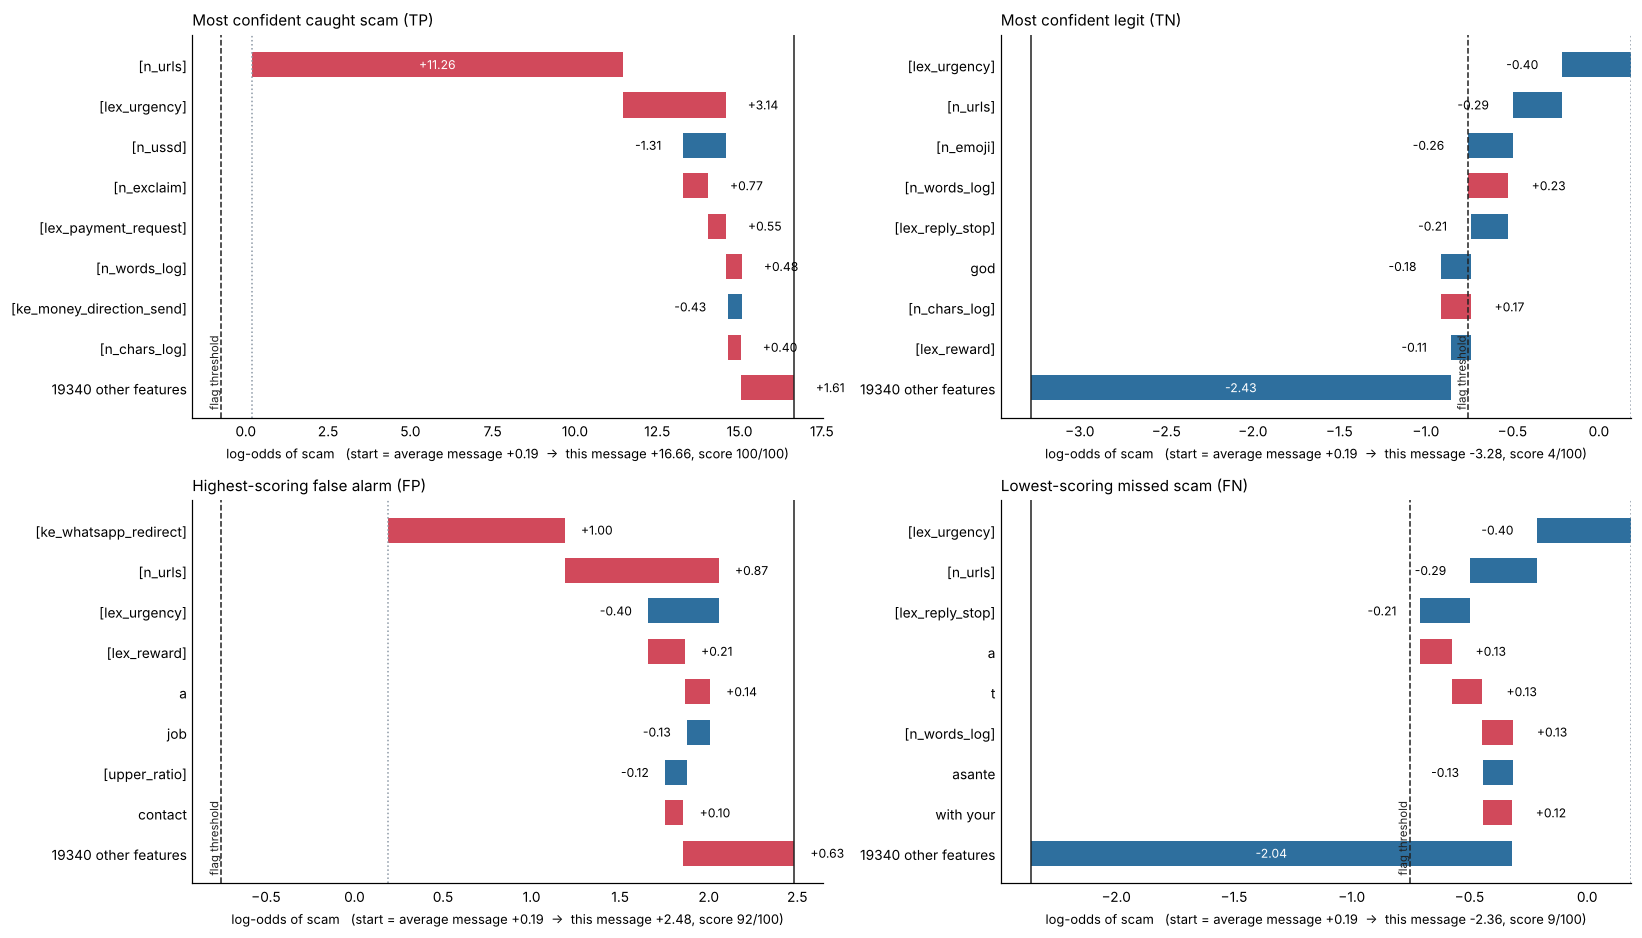

In [11]:
def pick(outcome, low=True):
    sub = te[te.outcome == outcome]
    return int(sub.score.idxmin() if low else sub.score.idxmax())
cases = [(pick('TP (scam caught)', low=False), 'Most confident caught scam (TP)'),
         (pick('TN (legit passed)', low=True),  'Most confident legit (TN)'),
         (pick('FP (false alarm)', low=False),  'Highest-scoring false alarm (FP)'),
         (pick('FN (missed scam)', low=True),   'Lowest-scoring missed scam (FN)')]
fig, axs = plt.subplots(2, 2, figsize=(15, 8.6))
for ax, (i, ttl) in zip(axs.ravel(), cases):
    plot_waterfall(sv, i, top=8, ax=ax, threshold_logit=THR_LOGIT, title=ttl)
plt.tight_layout(); save('shap_waterfalls')
for i, ttl in cases:
    print(f'--- {ttl} | label: {te.prelabel[i]} | score {te.score[i]*100:.0f}/100\n    ', te.message_content[i][:230].replace('\n', ' '))

**Reading**
* **Caught scam (TP, 100/100):** a flash-sale text with a shortened link; almost entirely the 10-link extrapolation above (+11.3) plus urgency (+3.1). The USSD code *reduces* the score (-1.3): the model has learned a negative weight for USSD codes, so this scam is caught despite it, not because of it.
* **Clean legit (TN, 4/100):** a devotional subscription message. No urgency, no link, "reply STOP" wording and an emoji all push towards legit; the biggest block is the sum of ~19,000 small word/char contributions (-2.4) - the vocabulary simply looks like benign religious content.
* **False alarm (FP, 92/100):** *"there is a job waiting for you to accept, the salary is high... wa.me/..."*. The dataset labels it legit; to most readers it looks like a classic job scam. The model flags it because of the WhatsApp redirect (+1.00) and the link (+0.87) - arguably the model is right and the **label is questionable**, which is consistent with the annotation caveat in the README.
* **Missed scam (FN, 9/100):** a subscription message ("Reply with 6 to subscribe. Dial *875*354#") labelled high-risk. It has no link, no urgency, no reward wording; the model has nothing scam-like to hold on to and the remaining vocabulary pulls it down by -2.0. This is the failure type notebook 04 found: short, link-free, subscription-trap messages.

## 5. Error analysis with SHAP
Instead of reading errors one by one, we compare the *average SHAP profile* of groups. Left: which features separate the scams the model **caught** from the ones it **missed**. Right: which features separate **false alarms** from correctly passed legit messages.

Missed scams: mean score 0.091 | caught scams: 0.847
False alarms by dataset label tier: {'0: Legit (Low-risk)': 14} | n = 14


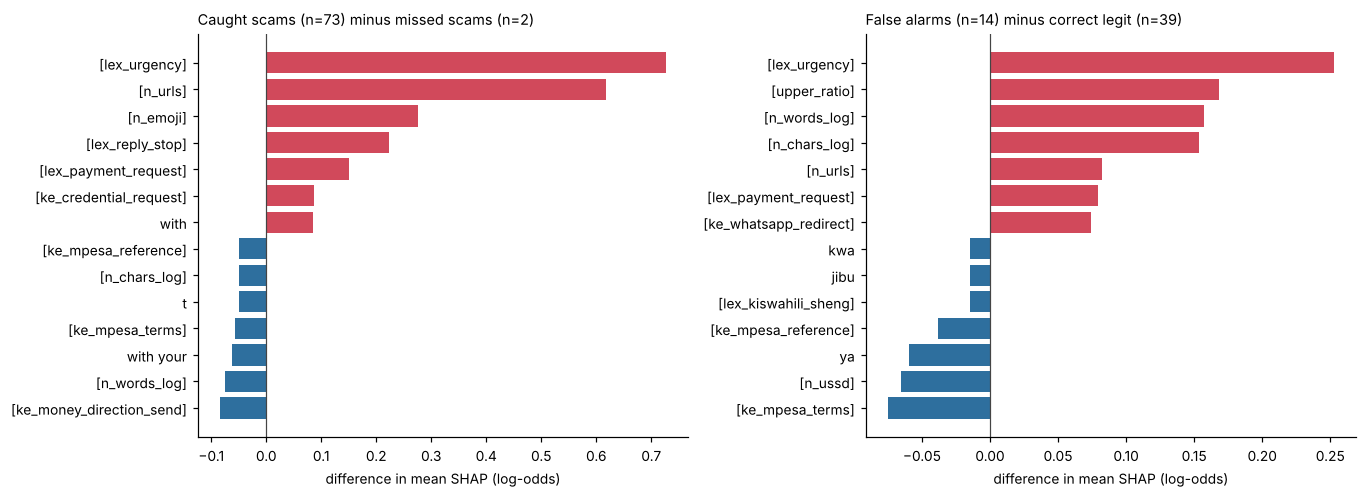

In [12]:
tp, fn = (te.outcome.str.startswith('TP')).values, (te.outcome.str.startswith('FN')).values
tn, fp = (te.outcome.str.startswith('TN')).values, (te.outcome.str.startswith('FP')).values
def contrast(a, b, k=7):
    diff = pd.Series(sv.values[a].mean(0) - sv.values[b].mean(0), index=sv.pretty)
    return pd.concat([diff.sort_values(ascending=False).head(k), diff.sort_values().head(k)[::-1]]).drop_duplicates()
c1, c2 = contrast(tp, fn), contrast(fp, tn)
fig, ax = plt.subplots(1, 2, figsize=(12.5, 4.6))
for a, c, ttl in [(ax[0], c1, f'Caught scams (n={tp.sum()}) minus missed scams (n={fn.sum()})'),
                  (ax[1], c2, f'False alarms (n={fp.sum()}) minus correct legit (n={tn.sum()})')]:
    c = c.sort_values()
    a.barh(c.index, c.values, color=np.where(c.values > 0, C_SCAM, C_LEGIT)); a.axvline(0, color='#444', lw=.8)
    a.set_title(ttl, loc='left', fontsize=9.5); a.set_xlabel('difference in mean SHAP (log-odds)')
    for s in ('top', 'right'): a.spines[s].set_visible(False)
plt.tight_layout(); save('shap_error_contrast')
print('Missed scams: mean score', te.score[fn].mean().round(3), '| caught scams:', te.score[tp].mean().round(3))
print('False alarms by dataset label tier:', te[fp].prelabel.value_counts().to_dict(), '| n =', int(fp.sum()))

**Reading**
* **Missed scams (n=2)** differ from caught scams chiefly by lacking `lex_urgency` (+0.73) and `n_urls` (+0.62) - the two features the model leans on most. Only two cases, so this is an illustration of the mechanism, not a statistic. The model is, in effect, "urgency-or-link detector plus extras"; a scam with neither is invisible to it.
* **False alarms (n=14)** are separated from correct passes by urgency wording, shouting (`upper_ratio`), length (`n_words_log`, `n_chars_log`) and links. All 14 carry the dataset's lowest tier (*Legit (Low-risk)*): they are typically **promotional or marketing messages** (supermarket deals, betting, loans) that legitimately use urgency and capitals - exactly the content the dataset places on the boundary between "legit" and "scam".
* Correct passes are pulled down by M-Pesa vocabulary (`ke_mpesa_terms`), USSD codes and Swahili function words (`ya`, `kwa`), i.e. genuine transactional / personal style.

## 6. The app's example messages, explained with the deployed model
These are the illustrative messages from `app.py` (invented, not dataset rows), scored by the **deployed** bundle with the training data it was fitted on as the background. They show the Kenya-aware features at work.

additivity error: 4.4e-16 | scores: {'Personal Kiswahili text': 7, 'Illustrative M-Pesa receipt': 5, 'Illustrative fake prize': 99, 'Illustrative reversal request': 82, 'Illustrative fake bank alert': 99}


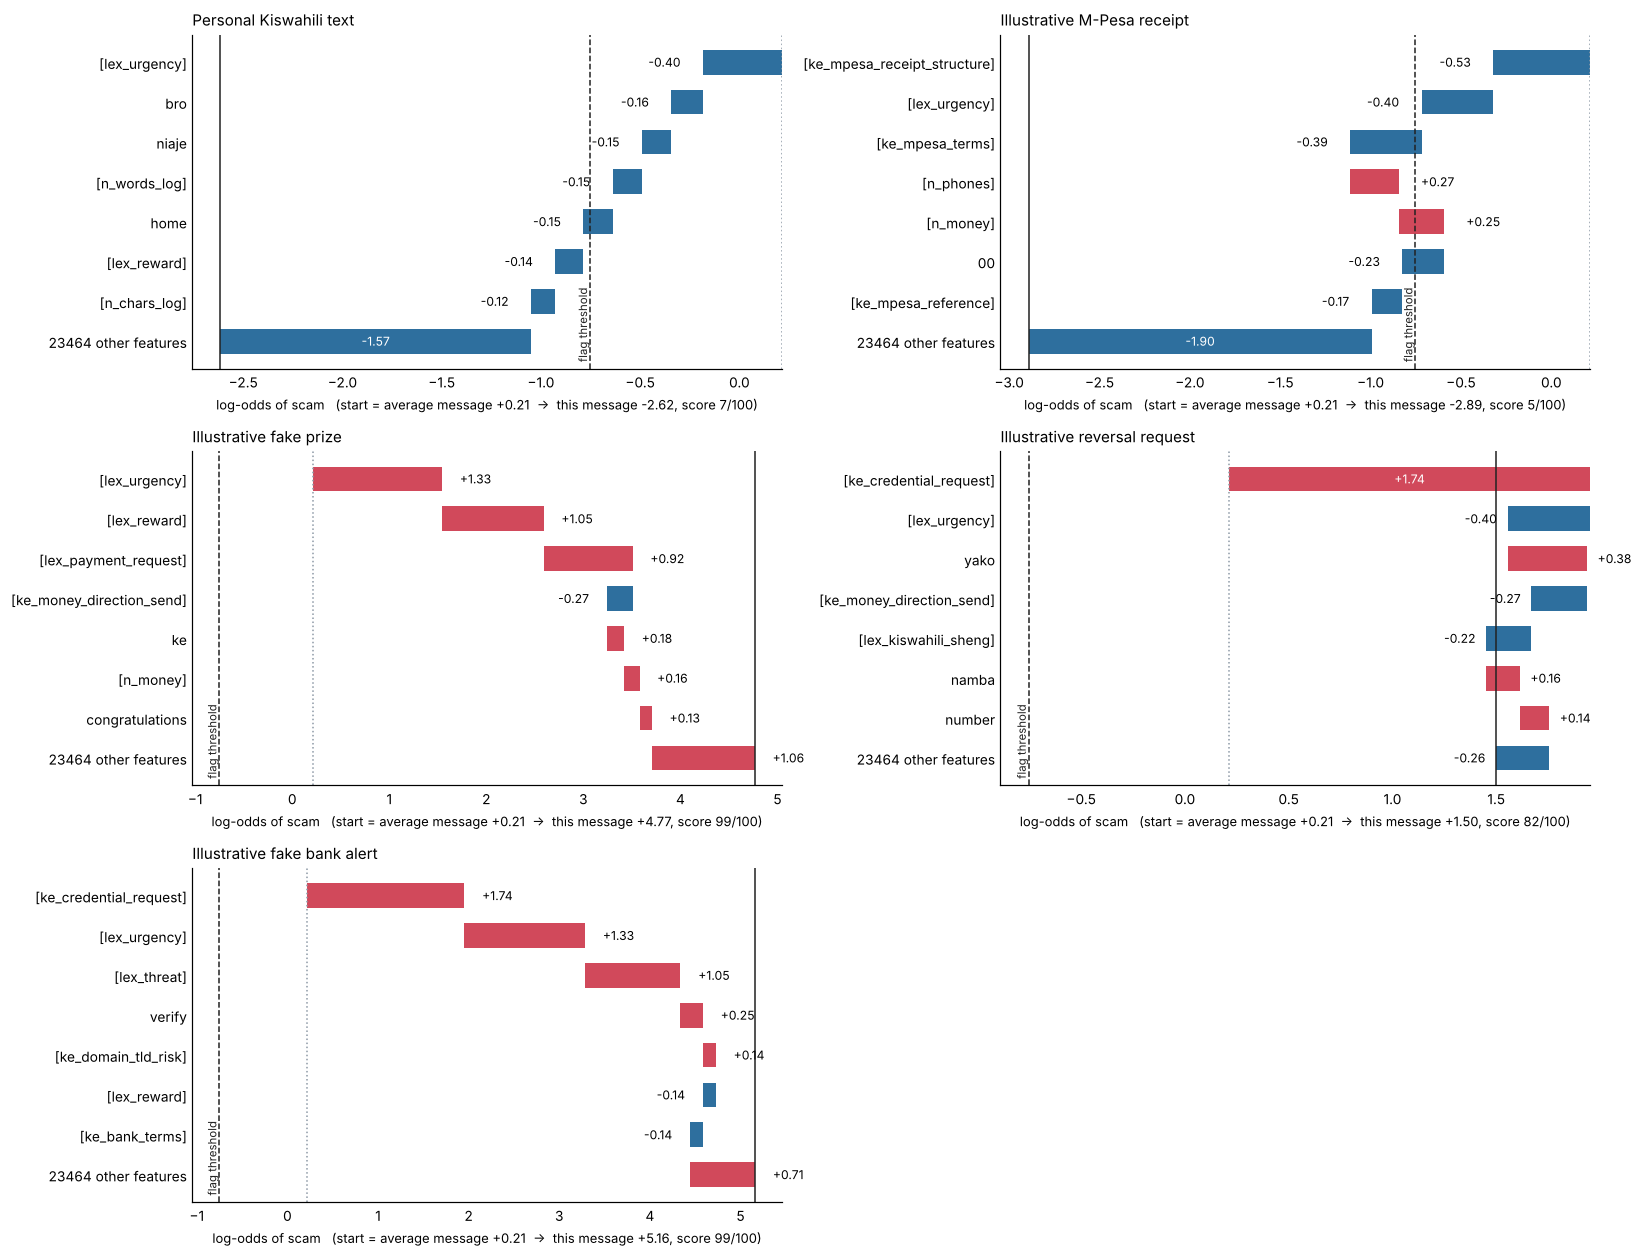

In [13]:
# The illustrative messages from the app (app.py), explained with the DEPLOYED bundle (fitted on all 643 + 80 synthetic messages)
# (the bundle was pickled from __main__, hence AdvancedFeatures is imported at the top of the notebook - same trick as app.py)
bundle = joblib.load(BUNDLE_PATH); dep = bundle['binary']
Xdep_bg = np.concatenate([clean.message_content.to_numpy(), syn.message_content.to_numpy()])
PROBES = {
 'Personal Kiswahili text':      'Niaje bro, nimefika home salama. Tutaonana kesho.',
 'Illustrative M-Pesa receipt':  'TQ82AB91CD Confirmed. Ksh2,500.00 sent to JOHN DOE 0712345678 on 2/11/26 at 6:20 PM. New M-Pesa balance is Ksh1,200.00. Transaction cost, Ksh25.00. Safaricom.',
 'Illustrative fake prize':      'CONGRATULATIONS! Umeshinda Ksh 250,000. Claim now. Pay Ksh 500 registration fee to receive your prize: bit.ly/claim-ke',
 'Illustrative reversal request':'Habari, nimetuma pesa kwa namba yako kimakosa. Tafadhali nitumie PIN yako au tuma Ksh 2,000 kwa hii number ili nireverse.',
 'Illustrative fake bank alert': 'KCB ALERT: Your account is BLOCKED. Verify your PIN and OTP immediately at http://kcb-secure-verify.xyz',
}
sp = linear_shap(dep, Xdep_bg, list(PROBES.values()))
print('additivity error:', f'{sp.additivity_error():.1e}', '| scores:', {k: round(float(p) * 100) for k, p in zip(PROBES, sp.prob)})
fig, axs = plt.subplots(3, 2, figsize=(15, 11.5)); axs = axs.ravel()
for i, name in enumerate(PROBES):
    plot_waterfall(sp, i, top=7, ax=axs[i], threshold_logit=THR_LOGIT, title=name)
axs[-1].axis('off')
plt.tight_layout(); save('shap_probe_waterfalls')

**Reading**
* **Personal Kiswahili text (7/100)** and **M-Pesa receipt (5/100)** both pass. The receipt is held down mainly by `ke_mpesa_receipt_structure` (-0.53, all of "Confirmed / balance / transaction cost" present) and M-Pesa terms (-0.39); it is pushed *up* slightly by phone number and money amount (+0.27, +0.25). It is the largest single contribution, so the Kenya-aware feature does real work here (the README warns that the app cannot verify that a receipt is genuine).
* **Fake prize (99/100)** is urgency + reward + payment wording (+1.33, +1.05, +0.92): the generic cues from section 3.
* **Reversal request (82/100)** is almost entirely `ke_credential_request` (+1.74): the model flags it *because it asks for a PIN*. The reversal wording itself is not a top contributor, and its score (82) is well below the other scams (99).
* **Fake bank alert (99/100)** combines the PIN/OTP request (+1.74), urgency (+1.33), threat wording (+1.05) and a risky domain ending (+0.14).
* Practical consequence: **a reversal scam that does not mention a PIN loses its biggest push** - removing that +1.74 would leave about 44/100, still above the 0.32 threshold but close to it. Worth testing on PIN-less reversal wording before relying on the app for that scam family.

## 7. The severity model (moderate vs high-risk)
Stage 2 only runs on messages the binary gate flags, so it is explained on those 87 test messages (16 moderate, 57 high, 14 legit false alarms). SHAP is computed per class on the logit scale: one explanation for "why moderate-risk", one for "why high-risk".

flagged messages: 87 (true tiers: moderate 16, high 57, legit false alarms 14)
additivity errors: 8.9e-16 5.3e-15


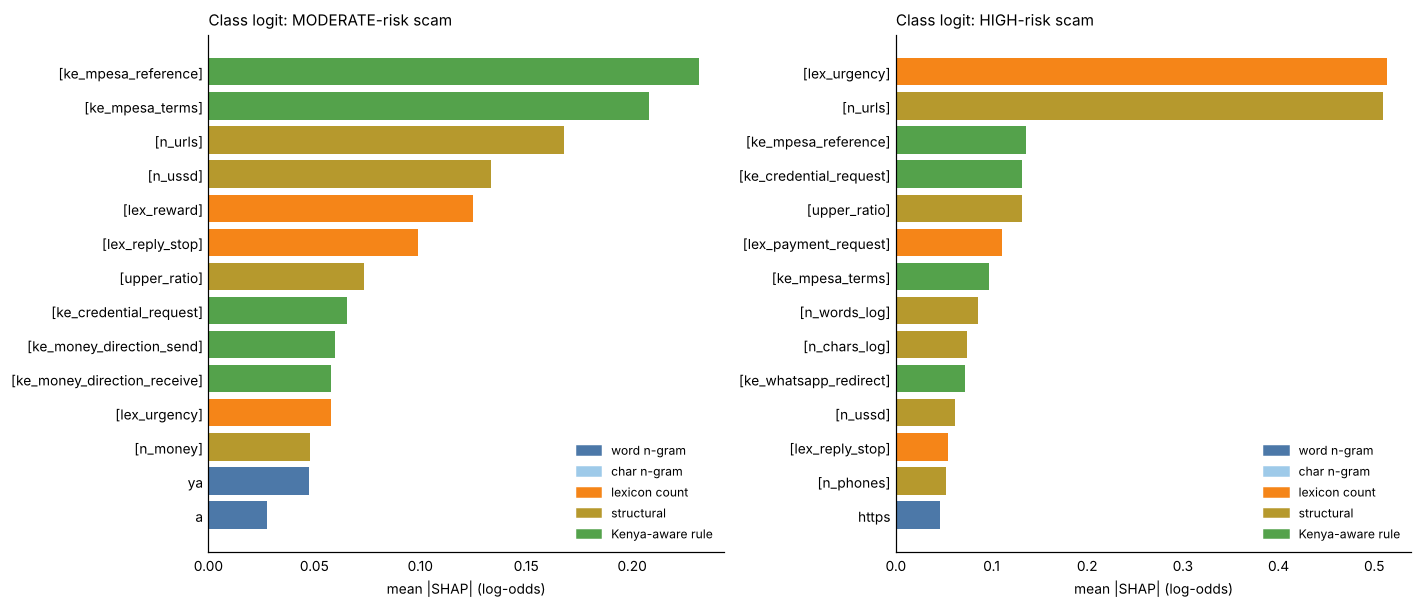

In [14]:
# Stage 2: which features separate MODERATE-risk from HIGH-risk scams?  Explained only for messages the binary gate flags,
# exactly as in deployment.  Each class logit has its own SHAP values (SHAP is computed per class on the logit scale).
flag = te.pred.values == 1
sv_mod = linear_shap(severity, Xtr, Xte[flag], class_index=1)
sv_high = linear_shap(severity, Xtr, Xte[flag], class_index=2)
print(f'flagged messages: {flag.sum()} (true tiers: moderate {(y3te[flag]==1).sum()}, high {(y3te[flag]==2).sum()}, legit false alarms {(y3te[flag]==0).sum()})')
print('additivity errors:', f'{sv_mod.additivity_error():.1e}', f'{sv_high.additivity_error():.1e}')
fig, ax = plt.subplots(1, 2, figsize=(13, 5.6))
plot_bar(sv_mod, top=14, ax=ax[0], title='mean |SHAP| (log-odds)'); ax[0].set_title('Class logit: MODERATE-risk scam', loc='left')
plot_bar(sv_high, top=14, ax=ax[1], title='mean |SHAP| (log-odds)'); ax[1].set_title('Class logit: HIGH-risk scam', loc='left')
plt.tight_layout(); save('shap_severity_bars')

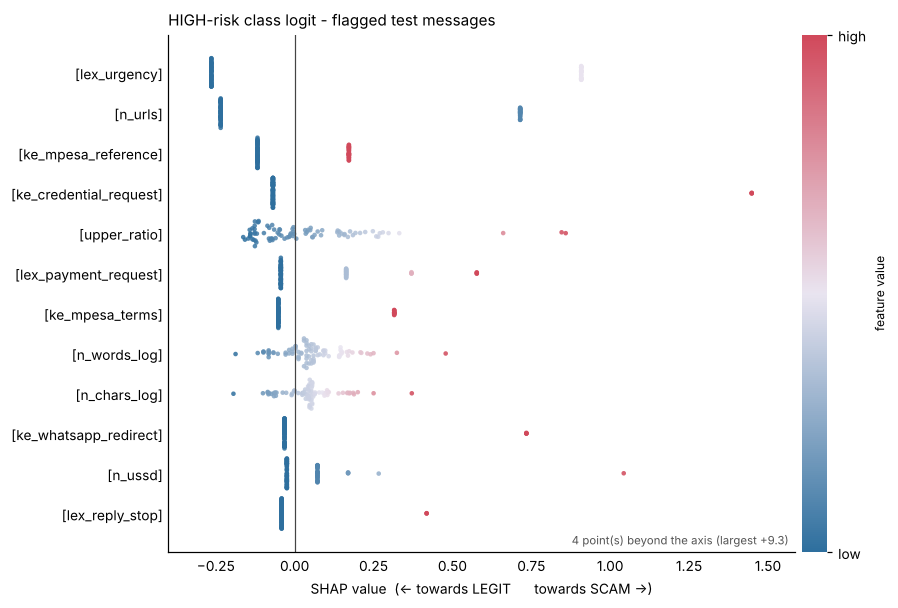

,moderate,high
feature,,
[n_urls],-0.066,0.202
[lex_urgency],-0.019,0.167
[n_ussd],-0.071,0.033
[n_words_log],-0.013,0.056
[lex_payment_request],-0.010,0.051
[n_chars_log],-0.006,0.049
[lex_reply_stop],0.046,-0.025
[lex_reward],0.033,0.006
[upper_ratio],-0.018,0.033


In [15]:
fig, ax = plt.subplots(figsize=(8.2, 5.6))
plot_beeswarm(sv_high, top=12, ax=ax); ax.set_title('HIGH-risk class logit - flagged test messages', loc='left')
plt.tight_layout(); save('shap_severity_beeswarm')
gm = pd.DataFrame({'feature': sv_high.pretty, 'moderate': sv_mod.values.mean(0), 'high': sv_high.values.mean(0)})
gm['abs'] = gm[['moderate', 'high']].abs().max(axis=1)
gm.sort_values('abs', ascending=False).head(10).drop(columns='abs').round(3).set_index('feature')

**Reading**
* **High-risk** is driven by the same two signals as the binary gate, `lex_urgency` (0.51) and `n_urls` (0.51). In the signed table, a link adds +0.20 and urgency +0.17 to the high-risk logit on average.
* **Moderate-risk** is driven by different cues: M-Pesa vocabulary and the (flawed, see 3.4) `ke_mpesa_reference` rule, USSD codes, `lex_reward` and "reply STOP" wording. A link *lowers* the moderate logit (-0.07) and USSD codes too (-0.07).
* So the severity model largely learns **"links + urgency = high-risk; subscription / reward / USSD style = moderate"**. That matches the source dataset's `prelabel` tiers but, as the README stresses, these are severity annotations, not scam families. With only 16 moderate examples in the test set the moderate-class explanation is noticeably less certain.

## 8. Can we trust the explanations themselves?
### 8.1 Stability across refits
Explanations from one model fit on 515 messages could be an accident of the sample. We refit the binary model on 30 bootstrap resamples of the training data, re-explain the test set each time, and track the rank of the 12 top features (1 = most important).

Spearman agreement of global importance, held-out-protocol model vs deployed model: 0.93


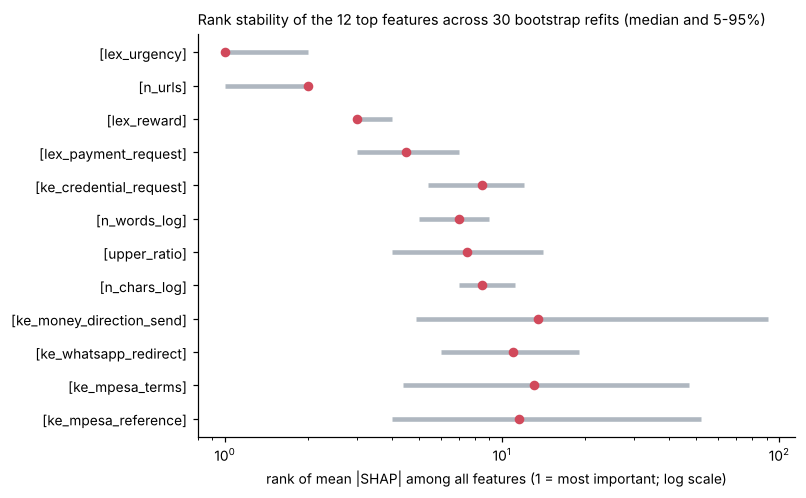

,median rank,5th pct,95th pct,in top-10 (% refits),in top-20 (% refits)
[lex_urgency],1.0,1.0,2.0,100.0,100.0
[n_urls],2.0,1.0,2.0,100.0,100.0
[lex_reward],3.0,3.0,4.0,100.0,100.0
[lex_payment_request],4.5,3.0,7.0,100.0,100.0
[ke_credential_request],8.5,5.4,12.0,86.7,100.0
[n_words_log],7.0,5.0,9.0,100.0,100.0
[upper_ratio],7.5,4.0,14.0,80.0,100.0
[n_chars_log],8.5,7.0,11.1,93.3,100.0
[ke_money_direction_send],13.5,4.9,91.2,30.0,73.3
[ke_whatsapp_redirect],11.0,6.0,19.0,40.0,96.7


In [16]:
# Are the global explanations stable?  Refit the binary model on 30 bootstrap resamples of the training data, re-explain the test set.
B = 30; rng = np.random.default_rng(7)
ref = sv.global_importance().head(12)
ref_raw = ref.raw_name.tolist(); ranks = {r: [] for r in ref_raw}; top20_hits = {}
for b in range(B):
    ii = rng.integers(0, len(Xtr), len(Xtr))
    mb = build_advanced_pipeline(False).fit(Xtr[ii], ytr[ii])
    gb = linear_shap(mb, Xtr[ii], Xte).global_importance()
    rk = pd.Series(np.arange(1, len(gb) + 1), index=gb.raw_name)
    for r in ref_raw: ranks[r].append(rk.get(r, np.nan))
    for r in gb.raw_name[:20]: top20_hits[r] = top20_hits.get(r, 0) + 1
R = pd.DataFrame(ranks); R.columns = ref.feature.tolist()
summ = pd.DataFrame({'median rank': R.median(), '5th pct': R.quantile(.05), '95th pct': R.quantile(.95),
                     'in top-10 (% refits)': (R <= 10).mean() * 100, 'in top-20 (% refits)': (R <= 20).mean() * 100}).round(1)
fig, ax = plt.subplots(figsize=(7.4, 4.6))
yy = np.arange(len(summ))[::-1]
ax.hlines(yy, summ['5th pct'], summ['95th pct'], color=C_GREY, lw=3, alpha=.7)
ax.scatter(summ['median rank'], yy, color=C_SCAM, zorder=3, s=28)
ax.set_yticks(yy); ax.set_yticklabels(summ.index); ax.set_xscale('log'); ax.set_xlabel('rank of mean |SHAP| among all features (1 = most important; log scale)')
ax.set_title(f'Rank stability of the 12 top features across {B} bootstrap refits (median and 5-95%)', loc='left', fontsize=9.5)
for s in ('top', 'right'): ax.spines[s].set_visible(False)
plt.tight_layout(); save('shap_rank_stability')
rho_dep = spearmanr(sv.global_importance().set_index('raw_name').mean_abs_shap,
                    linear_shap(dep, Xdep_bg, Xte).global_importance().set_index('raw_name').mean_abs_shap.reindex(sv.global_importance().raw_name).values)[0]
print(f'Spearman agreement of global importance, held-out-protocol model vs deployed model: {rho_dep:.2f}')
summ

**Reading**
* The **top-4 features are rock solid**: `lex_urgency`, `n_urls`, `lex_reward` and `lex_payment_request` stay in the top 10 in 100% of refits (5-95% rank intervals: `lex_urgency` and `n_urls` 1-2, `lex_reward` 3-4, `lex_payment_request` 3-7).
* `ke_credential_request`, `n_words_log`, `upper_ratio` and `n_chars_log` are in the top 20 in 100% of refits (top 10 in 80-100%).
* The other **Kenya-aware rules are unstable**: `ke_money_direction_send` ranges from rank 5 to 91, `ke_mpesa_reference` 4-52, `ke_mpesa_terms` 4-47. Do not over-interpret their exact positions - they fire in few messages, so a handful of resampled rows moves them a lot.
* The explanation of the **deployed** model (fitted on all data) agrees with the held-out-protocol model: Spearman 0.93 on global importance. The conclusions above are not an artefact of holding out the test set.

### 8.2 Cross-check with the `shap` package
The cell below verifies our closed-form values against `shap.LinearExplainer` when the library is available.

In [17]:
# Optional cross-check against the `shap` package (pip install shap). Skipped automatically if it is not installed.
try:
    import shap
except ImportError:
    print('`shap` is not installed in this environment -> skipping the library cross-check.\n'
          'All values above come from the exact closed-form linear SHAP in src/explain.py; run `pip install shap` and re-run this cell to verify.')
else:
    res = crosscheck_with_shap(binary, Xtr, Xte, sv)
    print('shap version:', res['shap_version'], '| max |difference| vs closed form:', f"{res['max_abs_diff']:.2e}",
          '| expected-value difference:', f"{res['base_diff']:.2e}", '| agree:', res['agrees'])

`shap` is not installed in this environment -> skipping the library cross-check.
All values above come from the exact closed-form linear SHAP in src/explain.py; run `pip install shap` and re-run this cell to verify.


### 8.3 Saved outputs
Tables for the report and figures (all prefixed `shap_`) are written to `reports/` and `reports/figures/`.

In [18]:
sv.global_importance().drop(columns='raw_name').to_csv(ROOT / 'reports' / 'shap_global_importance_binary.csv', index=False)
pd.concat([sv_mod.global_importance().assign(class_logit='moderate-risk'),
           sv_high.global_importance().assign(class_logit='high-risk')]).drop(columns='raw_name') \
  .to_csv(ROOT / 'reports' / 'shap_global_importance_severity.csv', index=False)
rows = []
for i in range(len(te)):
    o = np.argsort(-np.abs(sv.values[i]))[:5]
    rows.append({'message': te.message_content[i][:120].replace('\n', ' '), 'label': te.label[i], 'score': round(float(te.score[i]), 3),
                 'outcome': te.outcome[i], 'top_contributions': '; '.join(f'{sv.pretty[j]} ({sv.values[i, j]:+.2f})' for j in o)})
pd.DataFrame(rows).to_csv(ROOT / 'reports' / 'shap_test_local_explanations.csv', index=False)
print('saved: reports/shap_global_importance_binary.csv, shap_global_importance_severity.csv, shap_test_local_explanations.csv')
print('figures:', ', '.join(sorted(p.name for p in FIG.glob('shap_*.png'))))

saved: reports/shap_global_importance_binary.csv, shap_global_importance_severity.csv, shap_test_local_explanations.csv
figures: shap_beeswarm.png, shap_error_contrast.png, shap_families.png, shap_global_bar.png, shap_probe_waterfalls.png, shap_rank_stability.png, shap_severity_bars.png, shap_severity_beeswarm.png, shap_waterfalls.png


## 9. Summary and limitations
| Question | Answer (evidence above) |
|---|---|
| What does the binary model rely on? | Mainly **urgency wording** (mostly the word *now*) and **link count**, then reward / payment lexicon counts, PIN/OTP requests and length/capitalisation. Word and char n-grams add many small contributions (sections 3.1-3.3). |
| Do the Kenya-aware features matter? | Rarely on this dataset (family importance 0.23, no class separation), but strongly on PIN/OTP-style messages (section 6). Their global rank is unstable (8.1). |
| Why does it fail? | Scams with neither a link nor urgency are invisible (missed scams); promotional messages with urgency, capitals and links look like scams (false alarms) (section 5). |
| Anything wrong in the model itself? | Yes, two findings: **unbounded link count extrapolates** (10 links = +11 log-odds, section 3.2b) and **`ke_mpesa_reference` mostly matches ordinary 10-letter words** (3.4). Neither was changed here; both are recommended experiments. |
| Is the explanation trustworthy? | Exact for these linear models (additivity 1e-14), stable at the top across bootstrap refits, consistent with the baseline coefficients and with the deployed model (rho 0.93). |

### Limitations
* SHAP explains **the model, not the world**: "urgency raises the score" means the dataset's scams contain urgency words, not that urgency causes fraud.
* Values are **relative to the training background**; a different background (e.g. real inbox traffic, which is mostly legitimate) would shift the baseline and the sign of "absent feature" evidence.
* Correlated overlapping n-grams **share credit**, understating any single concept; the family view mitigates but does not remove this.
* 128 test messages (2 missed scams, 14 false alarms, 16 moderate-risk) are too few for statistical statements about error groups - they illustrate mechanisms.
* The log-odds scale is the model's scale; the 0-100 risk score is **not a calibrated probability** (see README).

### Suggested follow-ups (would change the model, so they need re-evaluation)
1. Cap or log-transform `n_urls` / other counts. 2. Tighten the `mpesa_reference` regex to require letters *and* digits. 3. Add real PIN-less reversal-scam examples before relying on the reversal-scam behaviour. 4. Optionally surface SHAP-based "absent evidence" in the app.